# Grid Search Analysis: GRN Inference Performance (Detailed)
This notebook analyzes the performance metrics without aggregating over different parameter configurations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set plotting style
sns.set_theme(style='whitegrid', context='talk')
os.makedirs('images/detailed', exist_ok=True)


In [2]:
# Load data
df = pd.read_csv('results/grid_results/performance_metrics.csv')
# We no longer drop duplicates because we want to keep all trials for seaborn to calculate confidence intervals
# df = df.drop_duplicates(subset=['dt_meas', 'M_pairs', 't_window_start', 't_window_end', 'N'], keep='last')

def label_window(row):
    if row['t_window_start'] == 0.0:
        return 'T'
    else:
        return 'S'
        
df['Regime'] = df.apply(label_window, axis=1)

# select rows where M <= 1000
df = df[df['M_pairs'] <= 1000]
df = df.reset_index(drop=True)

numeric_cols = ['TP', 'FP', 'FN', 'TN', 'TPR (Recall)', 'FPR', 'Precision', 'F1-Score', 'SHD']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


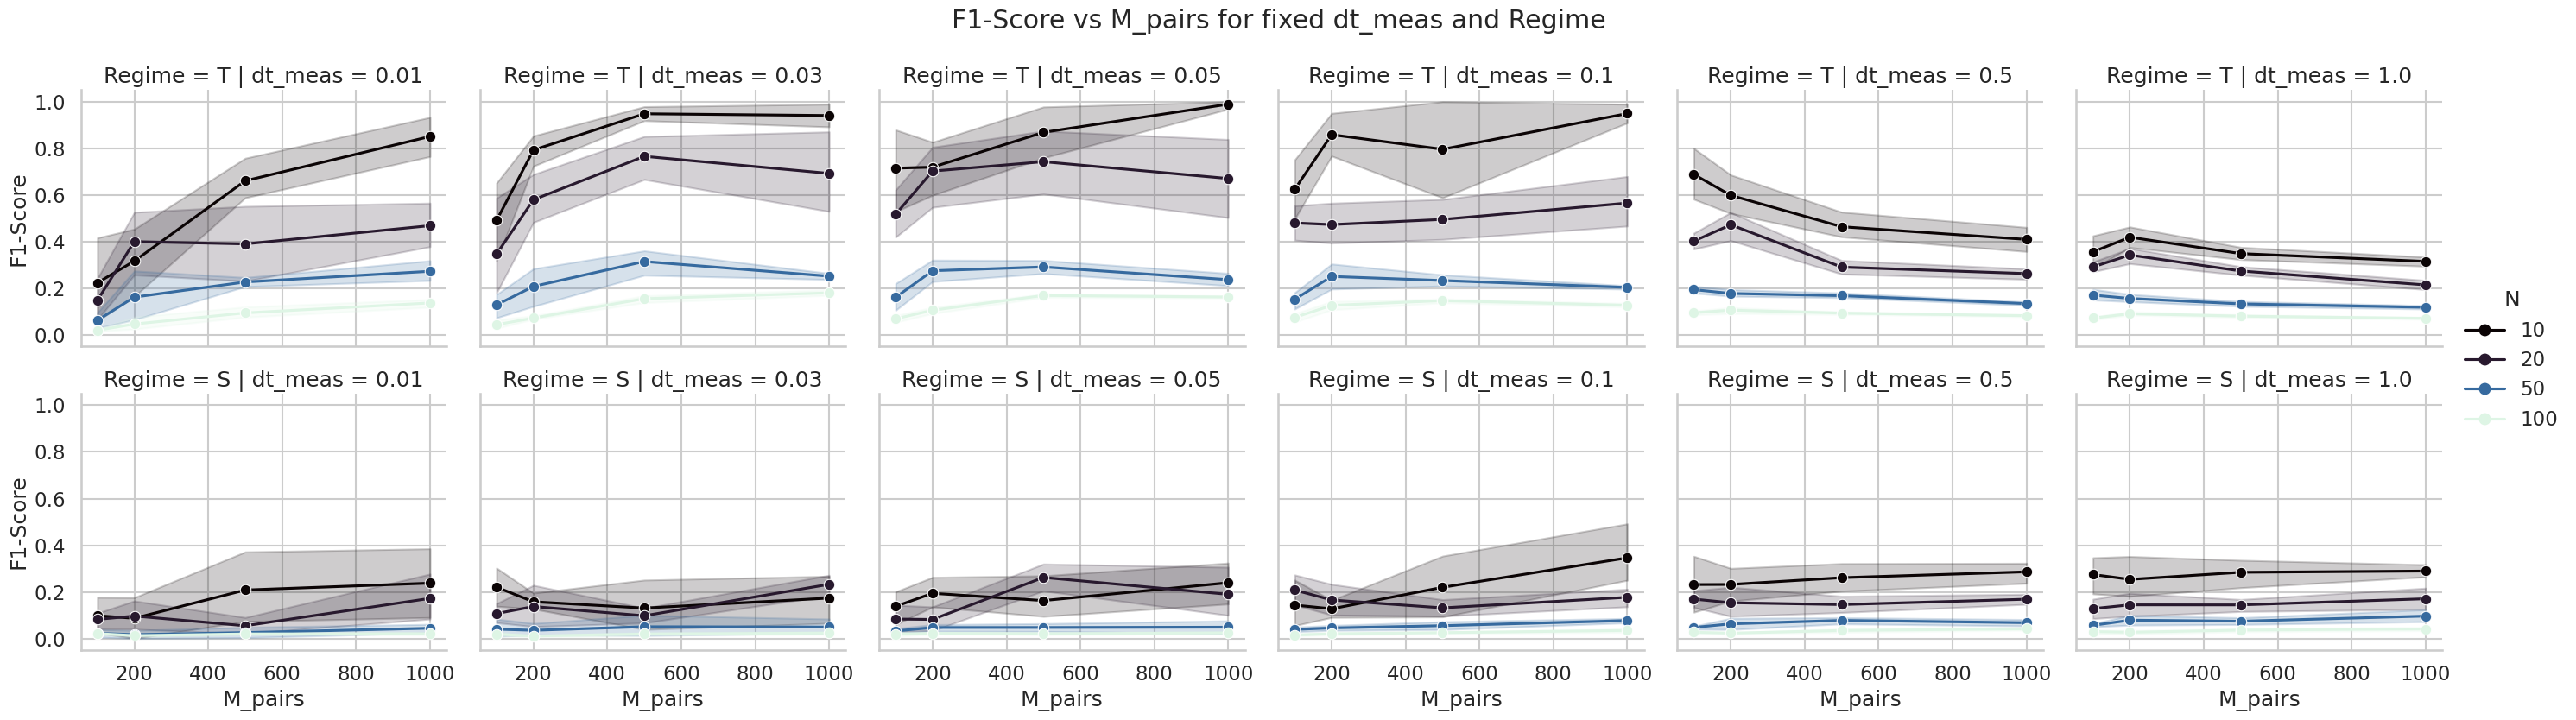

In [3]:
# Plot F1-Score vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='M_pairs', y='F1-Score', hue='N',
    col='dt_meas', row='Regime', kind='line', err_style='band', marker='o',
    palette='mako', height=4, aspect=1.2
)
#g.set(xlim=(0, 1100))
g.figure.suptitle('F1-Score vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


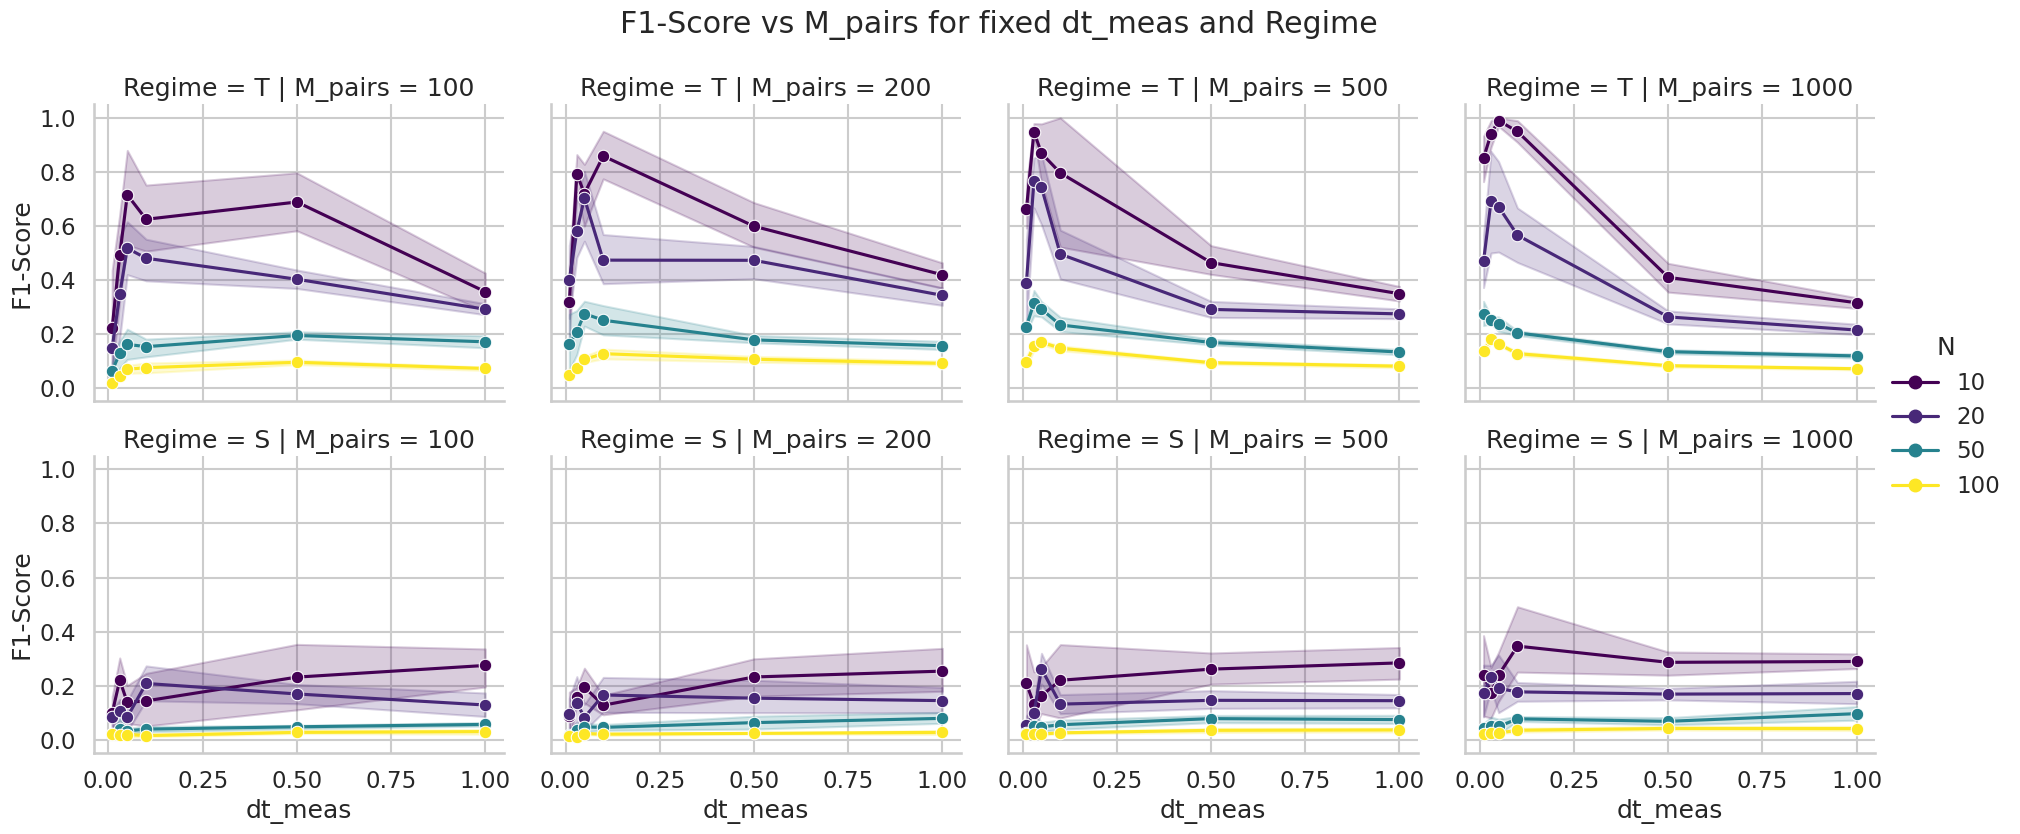

In [ ]:
# Plot F1-Score vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='dt_meas', y='F1-Score', hue='N',
    col='M_pairs', row='Regime', kind='line', err_style='band', marker='o',
    palette='viridis', height=4, aspect=1.2
)

g.set(xscale='log')
g.figure.suptitle('F1-Score vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


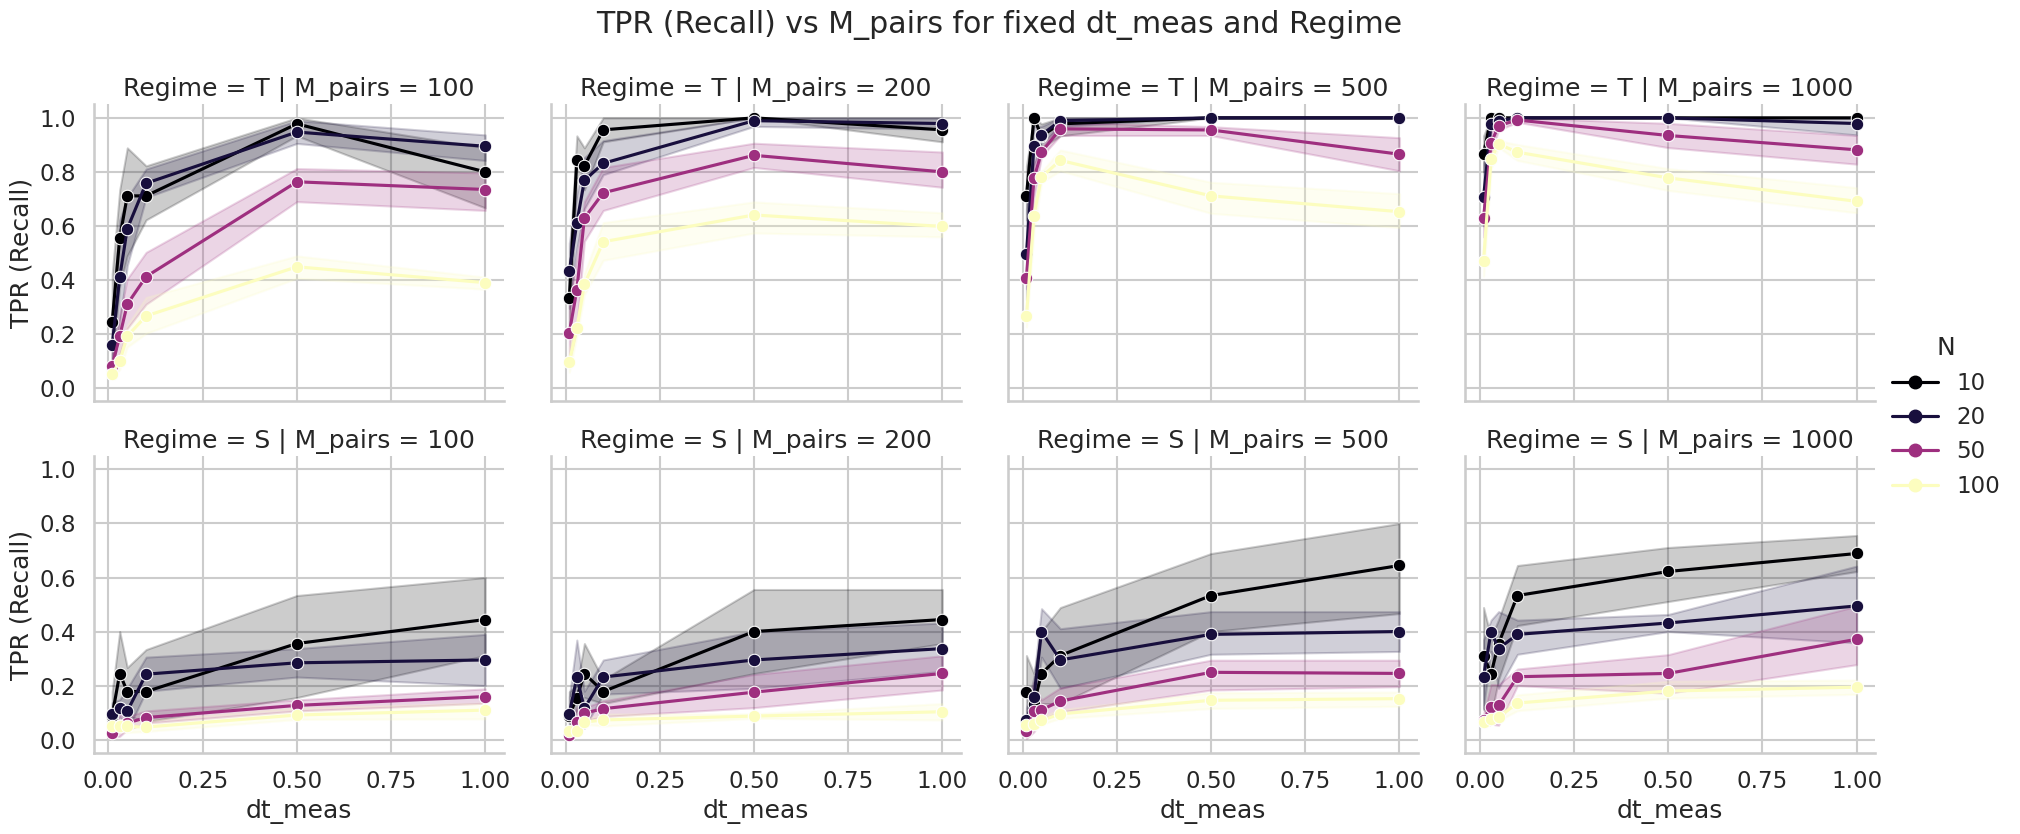

In [5]:
# Plot TPR (Recall) vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='dt_meas', y='TPR (Recall)', hue='N',
    col='M_pairs', row='Regime', kind='line', err_style='band', marker='o',
    palette='magma', height=4, aspect=1.2
)
#g.set(xlim=(0, 1100))
g.figure.suptitle('TPR (Recall) vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


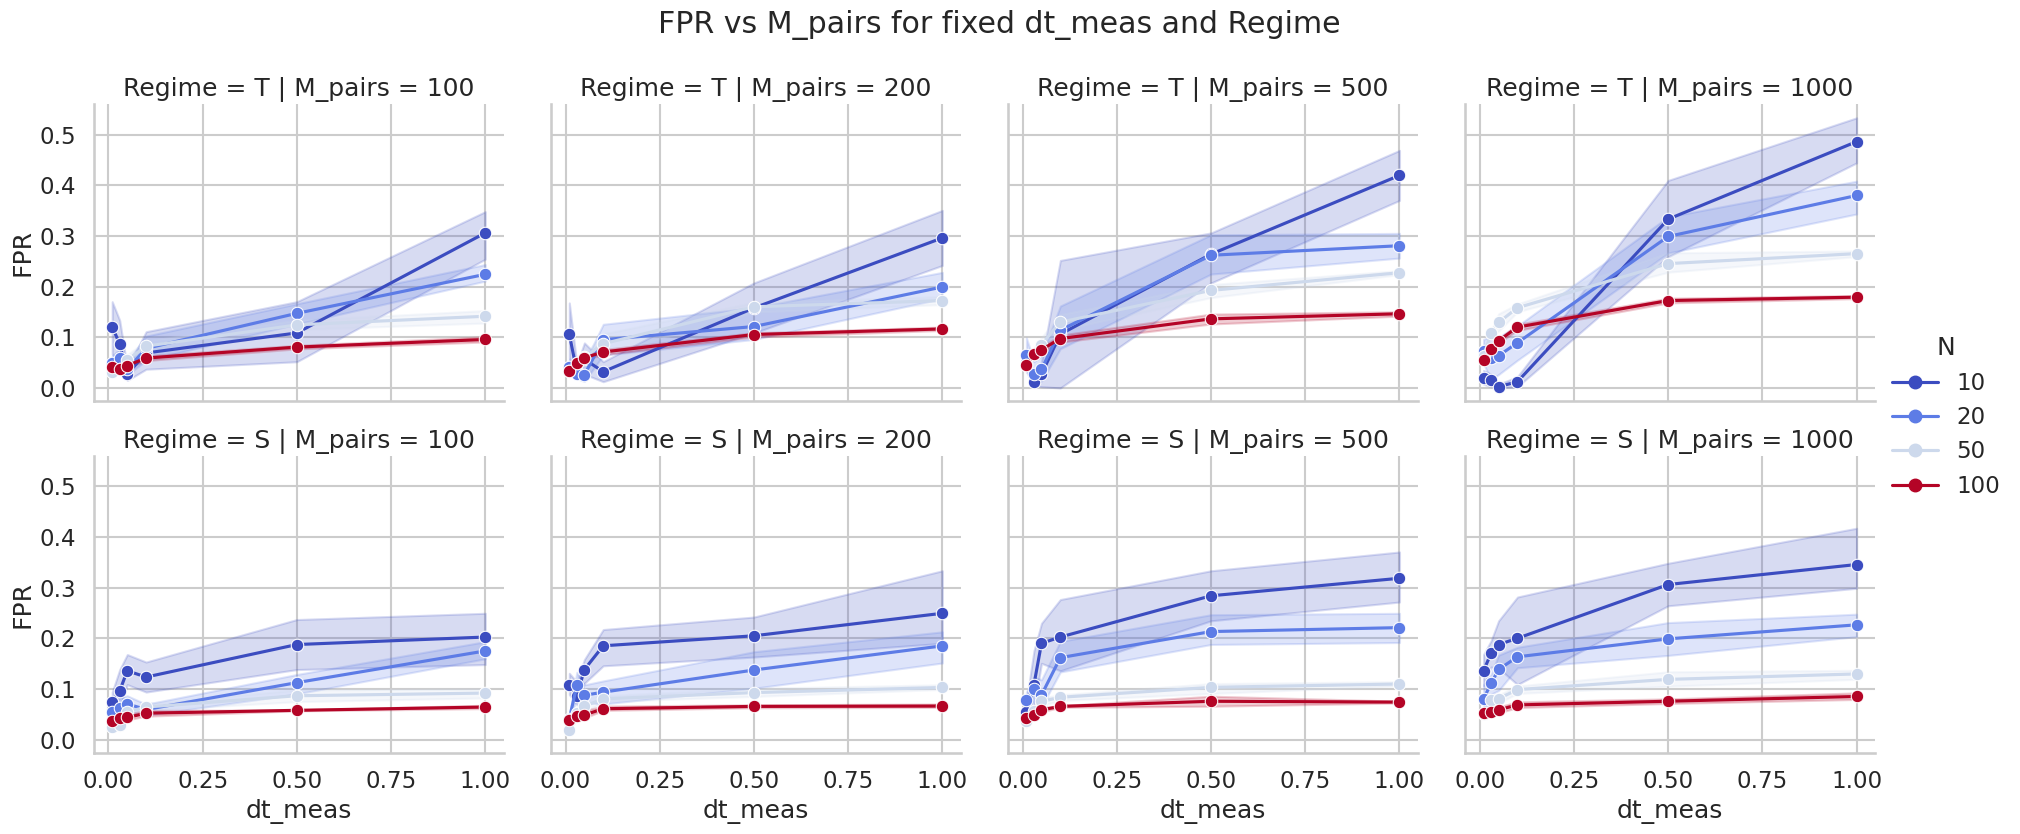

In [6]:
# Plot FPR vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='dt_meas', y='FPR', hue='N',
    col='M_pairs', row='Regime', kind='line', err_style='band', marker='o',
    palette='coolwarm', height=4, aspect=1.2
)
#g.set(xlim=(0, 1100))
g.figure.suptitle('FPR vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


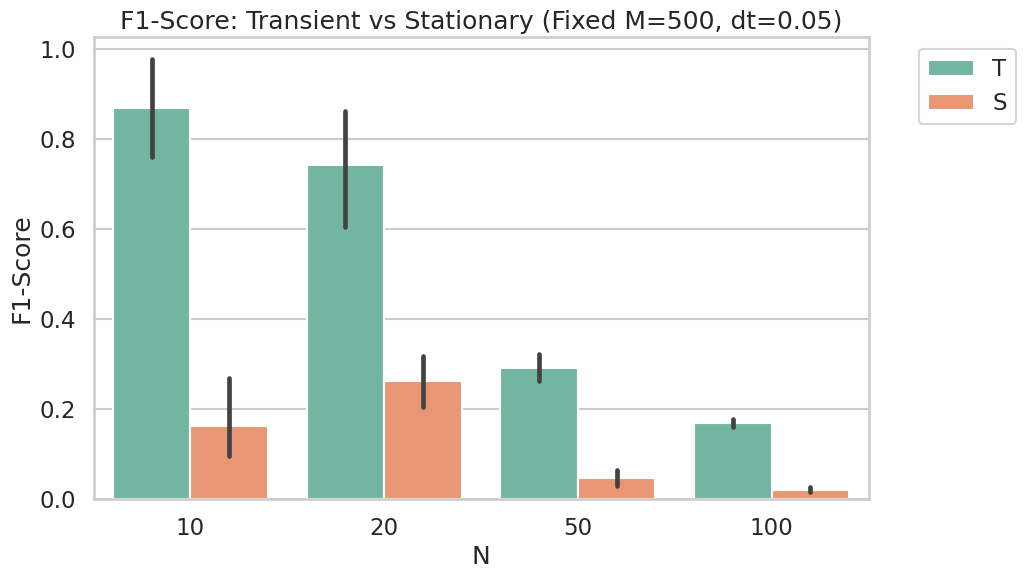

In [7]:
# Choose a specific configuration to compare transient vs stationary: M_pairs=500, dt_meas=0.05
fixed_M = 500
fixed_dt = 0.05
df_subset = df[(df['M_pairs'] == fixed_M) & (df['dt_meas'] == fixed_dt)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_subset, x='N', y='F1-Score', hue='Regime', palette='Set2', ax=ax)
ax.set_title(f'F1-Score: Transient vs Stationary (Fixed M={fixed_M}, dt={fixed_dt})')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('images/detailed/transient_vs_stationary_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


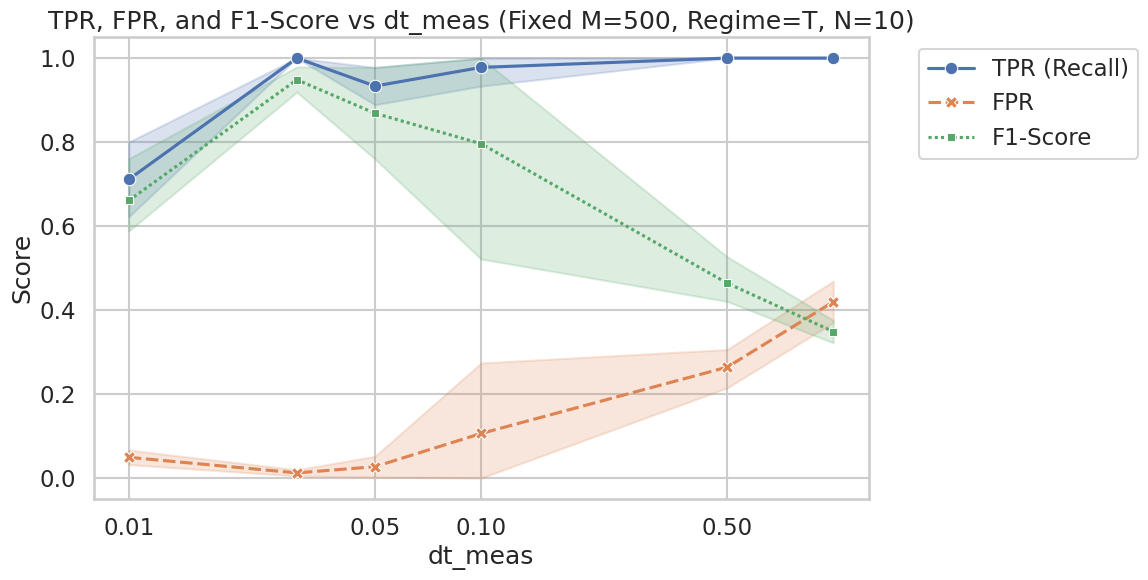

In [8]:
# Choose a specific configuration: M_pairs=500, Regime=Transient, N=10
fixed_Regime = 'T'
fixed_N = 10
df_dt = df[(df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

# Restructure the dataframe for seaborn to plot multiple metrics easily
df_melted = df_dt.melt(id_vars=['dt_meas'], value_vars=['TPR (Recall)', 'FPR', 'F1-Score'], 
                       var_name='Metric', value_name='Score')

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=df_melted, x='dt_meas', y='Score', hue='Metric', style='Metric', 
             markers=True, err_style='band', ax=ax)

ax.set_xlabel('dt_meas')
ax.set_ylabel('Score')
ax.set_xscale('log')
ax.set_xticks([0.01, 0.05, 0.1, 0.5])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_title(f'TPR, FPR, and F1-Score vs dt_meas (Fixed M={fixed_M}, Regime={fixed_Regime}, N={fixed_N})')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('images/detailed/metrics_comparison_single_N.png', dpi=300, bbox_inches='tight')
plt.show()

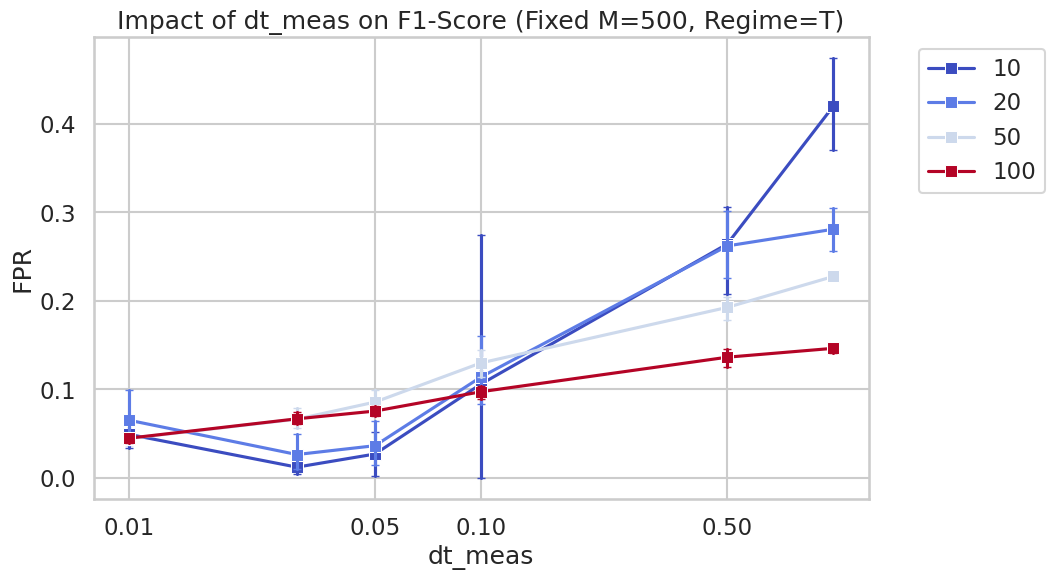

In [9]:
# Choose a specific configuration: M_pairs=500, Regime=Transient
fixed_Regime = 'T'
df_dt = df[(df['M_pairs'] == fixed_M) & (df['Regime'] == fixed_Regime)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(err_style='bars', err_kws={'capsize': 3}, data=df_dt, x='dt_meas', y='FPR', hue='N', marker='s', palette='coolwarm', ax=ax)
ax.set_title(f'Impact of dt_meas on F1-Score (Fixed M={fixed_M}, Regime={fixed_Regime})')
ax.set_xscale('log')
ax.set_xticks([0.01, 0.05, 0.1, 0.5])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('images/detailed/impact_of_dt_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


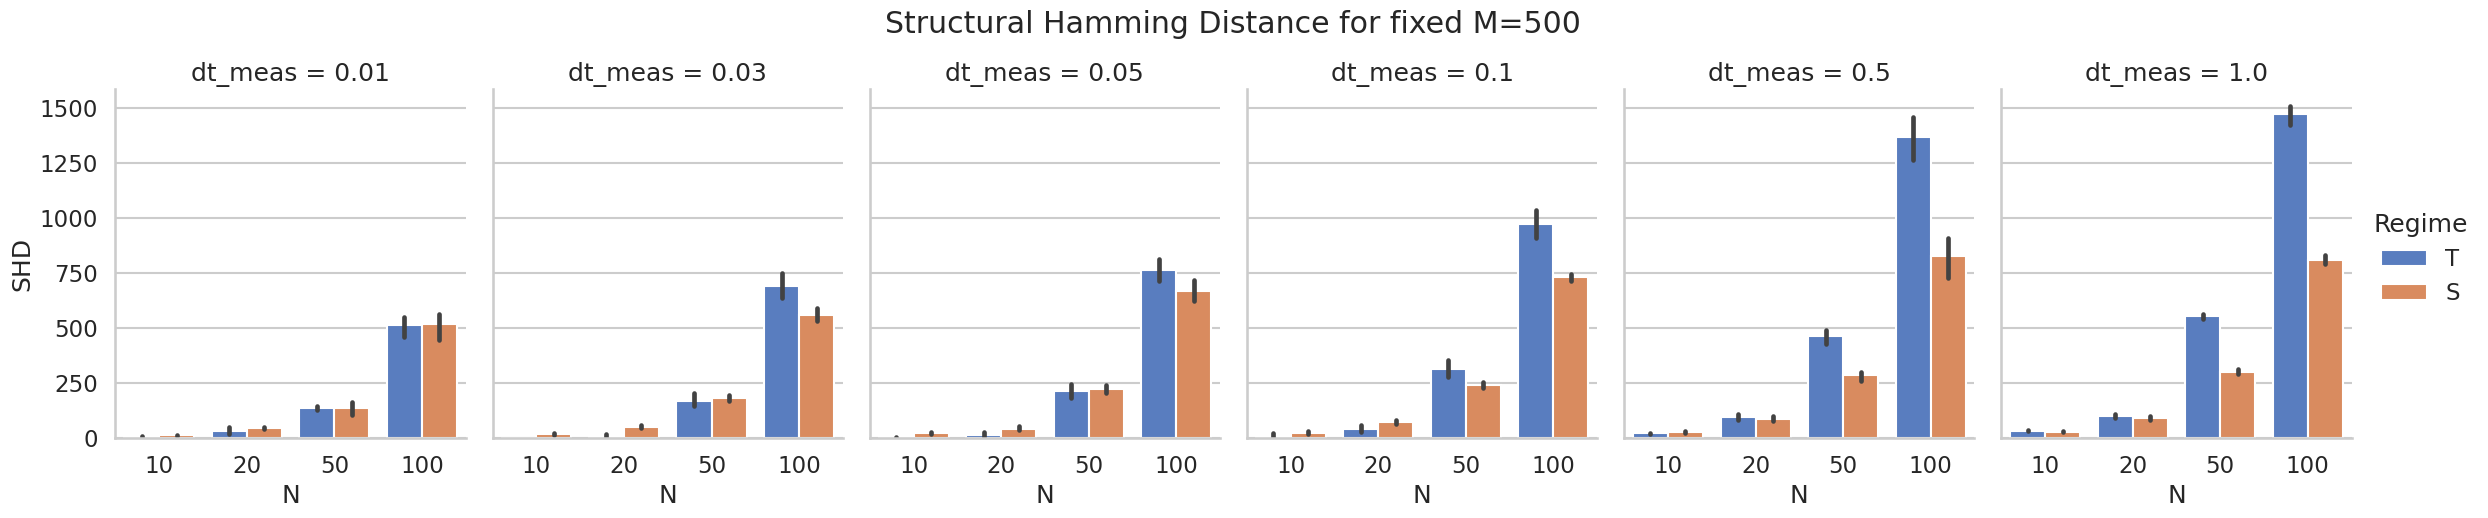

In [10]:
# Plot SHD vs N, faceted by Regime and dt_meas, for fixed M_pairs=500
g = sns.catplot(
    data=df[df['M_pairs'] == fixed_M], x='N', y='SHD', 
    hue='Regime', col='dt_meas', kind='bar',
    palette='muted', height=5, aspect=0.8
)
g.fig.suptitle(f'Structural Hamming Distance for fixed M={fixed_M}', y=1.05)
g.savefig('images/detailed/shd_faceted.png', dpi=300, bbox_inches='tight')
plt.show()
